библиотеки

In [14]:
import os
from pathlib import Path
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset

создание базы данных

In [15]:
base_dir = Path('data')

def create_dataframe(base_dir):
    data = []
    # Проходимся по training_set и testing_set
    for split in ['education_data', 'test_data']:
        split_dir = os.path.join(base_dir, split)
        for label_name in ['Опухоли нет','Гипофиз', 'Глиома', 'Менингиома']:
            folder_path = os.path.join(split_dir, label_name)

            if label_name == 'Опухоли нет':
                label = 0
            elif label_name == 'Гипофиз':
                label = 1
            elif label_name == 'Глиома':
                label = 2
            else:
                label = 3

            for img_name in os.listdir(folder_path):
                if img_name.lower().endswith(('.png', '.jpg', '.jpeg')):
                    img_path = os.path.join(folder_path, img_name)
                    data.append({
                        'filepath': img_path,
                        'label': label,
                        'split': 'train' if split == 'education_data' else 'test'
                                })

    df = pd.DataFrame(data)
    print(f"Всего изображений: {len(df)}")
    print(f"train: {len(df[df['split'] == 'train'])}, test: {len(df[df['split'] == 'test'])}")
    return df

df = create_dataframe(base_dir)

Всего изображений: 19264
train: 15250, test: 4014


In [16]:
print(df.to_string())

                                                    filepath  label  split
0                  data\education_data\Опухоли нет\1 no.jpeg      0  train
1                  data\education_data\Опухоли нет\10 no.jpg      0  train
2                  data\education_data\Опухоли нет\11 no.jpg      0  train
3                  data\education_data\Опухоли нет\12 no.jpg      0  train
4                  data\education_data\Опухоли нет\13 no.jpg      0  train
5                  data\education_data\Опухоли нет\14 no.jpg      0  train
6                  data\education_data\Опухоли нет\15 no.jpg      0  train
7                   data\education_data\Опухоли нет\1587.jpg      0  train
8                   data\education_data\Опухоли нет\1588.jpg      0  train
9                   data\education_data\Опухоли нет\1589.jpg      0  train
10                  data\education_data\Опухоли нет\1590.jpg      0  train
11                  data\education_data\Опухоли нет\1591.jpg      0  train
12                  data\

Выделение val:
5-и блоковая кросс-валидация - 
теперь индексы деления снимков на train и val для каждого блока хранятся в массиве folds

In [17]:
from sklearn.model_selection import StratifiedKFold

edu = df[df['split'] == 'train']

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
folds = []

folds = [
    (train_rows, val_rows)
    for train_rows, val_rows in skf.split(edu, edu['label'])
]

for fold, _ in enumerate(folds):
    train_idx = folds[fold][0]
    val_idx = folds[fold][1]
    
    distribution = pd.DataFrame({
        'train': edu.iloc[train_idx]['label'].value_counts(),
        'val': edu.iloc[val_idx]['label'].value_counts()
    }).fillna(0).astype(int)
    distribution.index.name = 'label'
    
    print(f'\nFold {fold}')
    print(distribution.to_string())


Fold 0
       train  val
label            
2       3534  884
1       3123  781
3       2867  716
0       2676  669

Fold 1
       train  val
label            
2       3534  884
1       3123  781
3       2867  716
0       2676  669

Fold 2
       train  val
label            
2       3535  883
1       3123  781
3       2866  717
0       2676  669

Fold 3
       train  val
label            
2       3535  883
1       3123  781
3       2866  717
0       2676  669

Fold 4
       train  val
label            
2       3534  884
1       3124  780
3       2866  717
0       2676  669


In [18]:
print(folds)

[(array([    0,     1,     2, ..., 15247, 15248, 15249], shape=(12200,)), array([    9,    14,    15, ..., 15223, 15239, 15244], shape=(3050,))), (array([    1,     2,     5, ..., 15247, 15248, 15249], shape=(12200,)), array([    0,     3,     4, ..., 15229, 15233, 15243], shape=(3050,))), (array([    0,     1,     3, ..., 15244, 15245, 15247], shape=(12200,)), array([    2,     7,    11, ..., 15246, 15248, 15249], shape=(3050,))), (array([    0,     2,     3, ..., 15246, 15248, 15249], shape=(12200,)), array([    1,    12,    17, ..., 15235, 15242, 15247], shape=(3050,))), (array([    0,     1,     2, ..., 15247, 15248, 15249], shape=(12200,)), array([    5,     6,     8, ..., 15230, 15238, 15245], shape=(3050,)))]


создание класса датасета для пайторч или монаи

In [19]:
class SnimkyDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]
        image = self.transform(str(row["filepath"]))
        label = int(row["label"])
        return image, label

предобработка изображений

In [20]:
from monai.transforms import (
    Compose, LoadImage, EnsureChannelFirst, CropForeground,
    ScaleIntensityRangePercentiles, Resize, SpatialPad, EnsureType,
)
from monai.data import PILReader

preprocess = Compose([
    LoadImage(
        image_only=True,
        reader=PILReader(converter=lambda im: im.convert('L')),
    ),
    EnsureChannelFirst(channel_dim="no_channel"),
    CropForeground(select_fn=lambda x: x > 10),
    ScaleIntensityRangePercentiles(lower=1, upper=99, b_min=0.0, b_max=1.0, clip=True),
    Resize(spatial_size=224, size_mode="longest", mode="area"),
    SpatialPad(spatial_size=(224, 224,), method="symmetric"),
    EnsureType(dtype=torch.float32),
])

Проверка предобработки

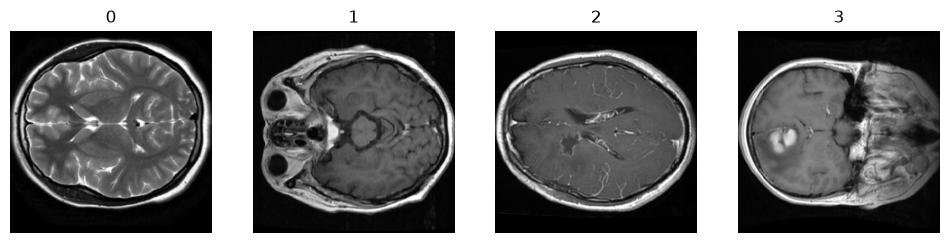

In [21]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 4, figsize=(12, 3))
for k in range(4):
    p = df[df['label'] == k].iloc[0]['filepath']
    ax[k].imshow(preprocess(p)[0], cmap='gray')
    ax[k].set_title(k); ax[k].axis('off')
plt.show()

ВАЖНО - я не прогоняла полную выборку, поэтому поставила батчи по 4 снимка. Нужно будет заменить обратно. Аугментация: так как при кросс-валидации объекты val постоянно меняются, наиболее рациональным мне кажется хранение двух датафреймов - аугментрованного и обычного. При обучении программа будет вызывать объекты с нужными индексами для каждого фолда.
Также я создала массив из загрузчиков для каждого фолда. Это можно сделать быстрее в блоке с обучением, но рас уж у нас вся аугментация здесь, пусть они будут в одном месте. На данном этапе между экономией и читаемостью приоритет как будто в читаемости.

In [22]:
from monai.transforms import RandRotate, RandAffine, RandAdjustContrast

augment = Compose([
    RandRotate(range_x=0.17, prob=0.5),
    RandAffine(translate_range=(10, 10), scale_range=(0.1, 0.1), prob=0.5),
    RandAdjustContrast(gamma=(0.8, 1.2), prob=0.3),
])

train_df = df[df['split'] == 'train']
val_df = df[df['split'] == 'train']
test_df = df[df['split'] == 'test']

train_ds = SnimkyDataset(train_df, transform=Compose([preprocess, augment]))
val_ds = SnimkyDataset(val_df, transform=preprocess)
test_ds = SnimkyDataset(test_df, transform=preprocess)


fold_loaders = []  #загрузчики для каждой кросс-валидации
for train_idx, val_idx in folds: #idx or rows??

    train_ds_fold = Subset(train_ds, train_idx) 
    val_ds_fold = Subset(val_ds, val_idx)

    train_loader = DataLoader(train_ds_fold, batch_size=16, shuffle=True, drop_last=True)
    val_loader = DataLoader(val_ds_fold, batch_size=16, shuffle=False)
    fold_loaders.append((train_loader, val_loader))

test_loader = DataLoader(test_ds, batch_size=16, shuffle=False)

images, labels = next(iter(train_loader))
print(images.shape, labels)
print(fold_loaders)

torch.Size([16, 1, 224, 224]) tensor([1, 3, 3, 0, 0, 2, 2, 0, 3, 1, 3, 2, 0, 0, 0, 2])
[(<torch.utils.data.dataloader.DataLoader object at 0x000002630F9A2D20>, <torch.utils.data.dataloader.DataLoader object at 0x000002630F866D20>), (<torch.utils.data.dataloader.DataLoader object at 0x000002637FBE9820>, <torch.utils.data.dataloader.DataLoader object at 0x000002630F3AFEC0>), (<torch.utils.data.dataloader.DataLoader object at 0x000002630F8D9DF0>, <torch.utils.data.dataloader.DataLoader object at 0x000002637FF07650>), (<torch.utils.data.dataloader.DataLoader object at 0x000002630F958830>, <torch.utils.data.dataloader.DataLoader object at 0x000002630F9595B0>), (<torch.utils.data.dataloader.DataLoader object at 0x000002630F92B980>, <torch.utils.data.dataloader.DataLoader object at 0x000002630F901A00>)]


Создание модели (ResNet18): я нмного переписала функцию, так как для каждого фолда кросс-валидации нужна отдельная модель (я была не очень рада это понять...) Поскольку перед кажым циклом фолда её нужно обновлять, она теперь def

In [23]:
from torchvision import models

device = torch.device("cpu")
def create_model():
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

    old_conv = model.conv1
    new_conv = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
    with torch.no_grad():
        new_conv.weight.copy_(old_conv.weight.sum(dim=1, keepdim=True))
        model.conv1 = new_conv

    model.fc = nn.Linear(model.fc.in_features, 4)

    model = model.to(device)

    return model

model = create_model()
images, labels = next(iter(train_loader))
out = model(images.to(device))
print(out.shape)


torch.Size([16, 4])


Обучение

In [24]:
import time
import numpy as np
from sklearn.metrics import roc_auc_score

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)


def to_np(t):
    t = t.as_tensor() if hasattr(t, 'as_tensor') else t
    return t.detach().cpu().numpy()


def run_epoch(loader, train):
    model.train() if train else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_probs, all_labels = [], []

    with torch.set_grad_enabled(train):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * len(images)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += len(images)
            all_probs.append(to_np(torch.softmax(outputs, dim=1)))
            all_labels.append(to_np(labels))

    try:
        auc = roc_auc_score(np.concatenate(all_labels), np.concatenate(all_probs), multi_class='ovr')
    except ValueError:                      # например, в выборке не хватает какого-то класса
        auc = float('nan')
    return total_loss / total, correct / total, auc


EPOCHS = 5
CKPT = "checkpoint.pt"
start_epoch, best_score = 1, 0.0

#if Path(CKPT).exists():                      # продолжаем, если запускали раньше
    #ck = torch.load(CKPT, weights_only=True)
    #model.load_state_dict(ck['model'])
    #optimizer.load_state_dict(ck['optimizer'])
    #start_epoch, best_score = ck['epoch'] + 1, ck.get('best_score', 0.0)
    #print(f"Продолжаю с эпохи {start_epoch}")

#цикл для фолда - цикл для эпох внутри
fold_results = []
for fold, (train_loader, val_loader) in enumerate(fold_loaders):

    import copy
    model = create_model().to(device)
    optimizer = optim.Adam(model.parameters(), lr=1e-4)
    best_val_loss = float("inf")
    best_score = 0
    best_weights = None

    for epoch in range(start_epoch, EPOCHS + 1):
        t0 = time.time()
        train_loss, train_acc, train_auc = run_epoch(train_loader, train=True)
        val_loss, val_acc, val_auc = run_epoch(val_loader, train=False)

        print(f"Эпоха {epoch}/{EPOCHS} | "
            f"train: loss {train_loss:.3f}, acc {train_acc:.2f}, auc {train_auc:.3f} | "
            f"val: loss {val_loss:.3f}, acc {val_acc:.2f}, auc {val_auc:.3f} | "
            f"{(time.time() - t0) / 60:.1f} мин")

        score = val_auc if val_auc == val_auc else val_acc       # если AUC не посчитался, берём accuracy
        if score > best_score:
            best_score = score
            best_weights = copy.deepcopy(model.state_dict())

            torch.save(best_weights, f"best_model_fold_{fold + 1}.pt")

        torch.save({'model': model.state_dict(), 'optimizer': optimizer.state_dict(),
                    'epoch': epoch, 'best_score': best_score}, f"checkpoint_fold_{fold + 1}.pt")
    
     #сохранение результатов фолда   
    fold_results.append(best_weights)
    

    

Эпоха 1/5 | train: loss 0.226, acc 0.92, auc 0.990 | val: loss 0.084, acc 0.98, auc 0.999 | 29.0 мин
Эпоха 2/5 | train: loss 0.080, acc 0.98, auc 0.998 | val: loss 0.039, acc 0.99, auc 1.000 | 26.7 мин
Эпоха 3/5 | train: loss 0.054, acc 0.98, auc 0.999 | val: loss 0.036, acc 0.99, auc 1.000 | 26.4 мин
Эпоха 4/5 | train: loss 0.035, acc 0.99, auc 1.000 | val: loss 0.052, acc 0.98, auc 1.000 | 26.4 мин
Эпоха 5/5 | train: loss 0.031, acc 0.99, auc 1.000 | val: loss 0.067, acc 0.98, auc 1.000 | 26.4 мин
Эпоха 1/5 | train: loss 0.229, acc 0.92, auc 0.990 | val: loss 0.088, acc 0.97, auc 0.999 | 26.4 мин
Эпоха 2/5 | train: loss 0.081, acc 0.97, auc 0.999 | val: loss 0.052, acc 0.98, auc 0.999 | 26.9 мин
Эпоха 3/5 | train: loss 0.049, acc 0.99, auc 0.999 | val: loss 0.046, acc 0.99, auc 0.999 | 26.4 мин
Эпоха 4/5 | train: loss 0.040, acc 0.99, auc 1.000 | val: loss 0.053, acc 0.98, auc 0.999 | 26.2 мин
Эпоха 5/5 | train: loss 0.038, acc 0.99, auc 1.000 | val: loss 0.042, acc 0.99, auc 1.000 |

In [25]:
print(fold_results)

[OrderedDict({'conv1.weight': tensor([[[[-2.2946e-02, -4.1769e-02, -1.5140e-02,  ...,  1.7789e-01,
            5.0632e-02, -5.9811e-02],
          [ 7.3523e-02,  2.5441e-02, -3.3902e-01,  ..., -8.3639e-01,
           -4.1902e-01, -2.6124e-02],
          [ 3.0962e-03,  2.0758e-01,  9.1634e-01,  ...,  1.5776e+00,
            7.3065e-01,  2.0631e-01],
          ...,
          [-1.1119e-01,  3.0519e-02,  2.0003e-01,  ..., -9.1049e-01,
           -1.2476e+00, -7.7749e-01],
          [ 8.5801e-02,  9.5951e-02,  1.2689e-01,  ...,  1.2030e+00,
            1.1205e+00,  4.8318e-01],
          [-5.8976e-03,  5.7481e-03, -4.9593e-02,  ..., -4.4675e-01,
           -2.7676e-01, -4.3781e-02]]],


        [[[-2.0343e-02, -6.3884e-03,  4.9109e-02,  ...,  5.2527e-02,
            3.7953e-02, -1.0849e-01],
          [ 1.2778e-01,  1.6354e-01,  3.0544e-01,  ...,  6.9168e-01,
            6.4156e-01,  4.9983e-01],
          [-1.1134e-01, -3.7719e-02,  9.4371e-02,  ...,  3.4855e-01,
            3.7835e-01,  4

Оценка на тесте: добавила обсчёт каждого фолда и сравнительную таблицу в конец. Потом допишу формулы для дополнительных метрик и сделаю график по зависимости точности модели от значений гиперпараметров


Фолд 1
[{'fold': 1, 'accuracy': 0.963129048330842, 'f1_macro': 0.9636949218317296, 'auc_ovr_macro': 0.996655619370164}]
=== Отчёт по классам ===
              precision    recall  f1-score   support

 Опухоли нет      0.969     0.999     0.984       887
     Гипофиз      0.991     0.985     0.988      1026
      Глиома      0.954     0.940     0.947      1155
  Менингиома      0.937     0.933     0.935       946

    accuracy                          0.963      4014
   macro avg      0.963     0.964     0.964      4014
weighted avg      0.963     0.963     0.963      4014



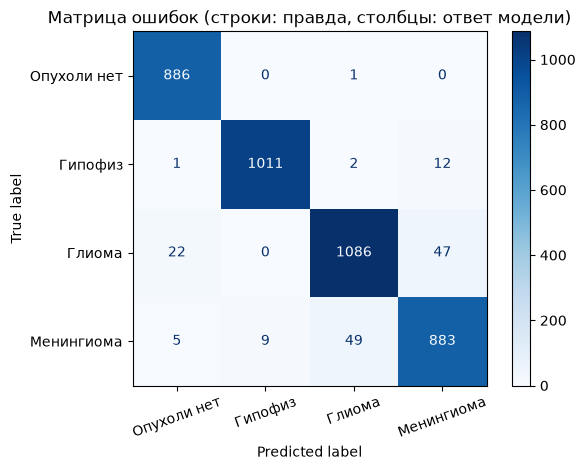

Матрица ошибок в % внутри настоящего класса:
             Опухоли нет  Гипофиз  Глиома  Менингиома
Опухоли нет         99.9      0.0     0.1         0.0
Гипофиз              0.1     98.5     0.2         1.2
Глиома               1.9      0.0    94.0         4.1
Менингиома           0.5      1.0     5.2        93.3

=== AUC (среднее по классам): 0.997
  Опухоли нет: 0.999
  Гипофиз: 1.000
  Глиома: 0.993
  Менингиома: 0.995

=== Опухоль / нет опухоли ===
Чувствительность: 0.991  (пропущено 28 из 3127)
Специфичность:    0.999  (ложных тревог 1 из 887)
AUC опухоль/нет:  0.999

Фолд 2
[{'fold': 2, 'accuracy': 0.9703537618335825, 'f1_macro': 0.9706937509885253, 'auc_ovr_macro': 0.9966120720387036}]
=== Отчёт по классам ===
              precision    recall  f1-score   support

 Опухоли нет      0.962     1.000     0.981       887
     Гипофиз      0.986     0.996     0.991      1026
      Глиома      0.975     0.939     0.956      1155
  Менингиома      0.957     0.953     0.955       946

 

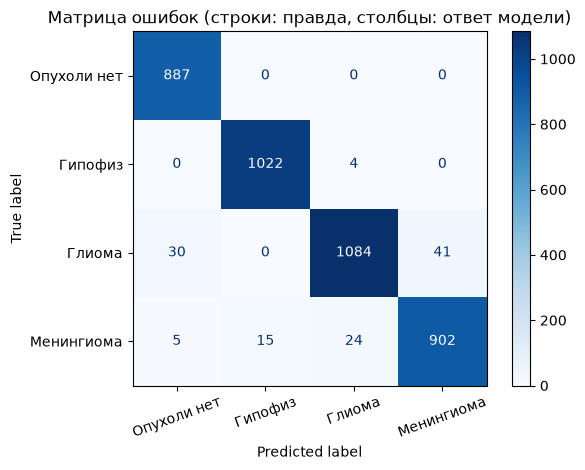

Матрица ошибок в % внутри настоящего класса:
             Опухоли нет  Гипофиз  Глиома  Менингиома
Опухоли нет        100.0      0.0     0.0         0.0
Гипофиз              0.0     99.6     0.4         0.0
Глиома               2.6      0.0    93.9         3.5
Менингиома           0.5      1.6     2.5        95.3

=== AUC (среднее по классам): 0.997
  Опухоли нет: 0.999
  Гипофиз: 1.000
  Глиома: 0.992
  Менингиома: 0.996

=== Опухоль / нет опухоли ===
Чувствительность: 0.989  (пропущено 35 из 3127)
Специфичность:    1.000  (ложных тревог 0 из 887)
AUC опухоль/нет:  0.999

Фолд 3
[{'fold': 3, 'accuracy': 0.9701046337817638, 'f1_macro': 0.9706175530645735, 'auc_ovr_macro': 0.9967984405952399}]
=== Отчёт по классам ===
              precision    recall  f1-score   support

 Опухоли нет      0.966     1.000     0.983       887
     Гипофиз      0.986     0.999     0.992      1026
      Глиома      0.971     0.934     0.952      1155
  Менингиома      0.956     0.955     0.955       946

 

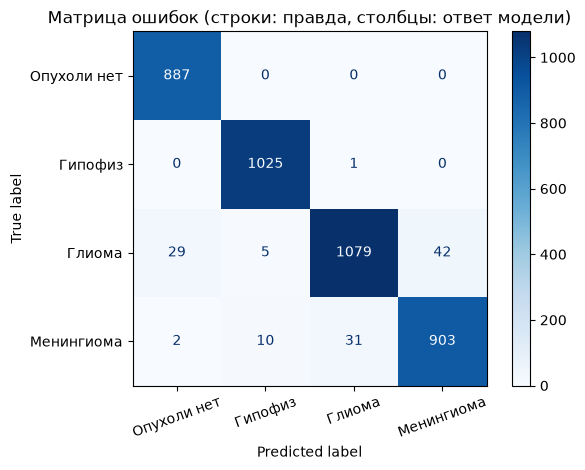

Матрица ошибок в % внутри настоящего класса:
             Опухоли нет  Гипофиз  Глиома  Менингиома
Опухоли нет        100.0      0.0     0.0         0.0
Гипофиз              0.0     99.9     0.1         0.0
Глиома               2.5      0.4    93.4         3.6
Менингиома           0.2      1.1     3.3        95.5

=== AUC (среднее по классам): 0.997
  Опухоли нет: 1.000
  Гипофиз: 1.000
  Глиома: 0.991
  Менингиома: 0.996

=== Опухоль / нет опухоли ===
Чувствительность: 0.990  (пропущено 31 из 3127)
Специфичность:    1.000  (ложных тревог 0 из 887)
AUC опухоль/нет:  1.000

Фолд 4
[{'fold': 4, 'accuracy': 0.965869456900847, 'f1_macro': 0.9664597947680079, 'auc_ovr_macro': 0.9970176920416377}]
=== Отчёт по классам ===
              precision    recall  f1-score   support

 Опухоли нет      0.971     0.999     0.985       887
     Гипофиз      0.971     0.995     0.983      1026
      Глиома      0.981     0.921     0.950      1155
  Менингиома      0.938     0.958     0.948       946

  

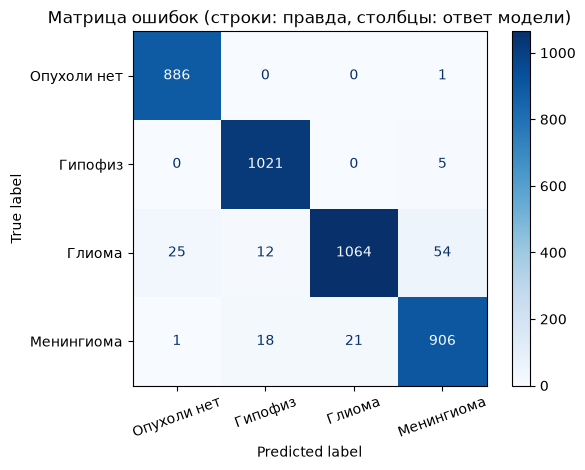

Матрица ошибок в % внутри настоящего класса:
             Опухоли нет  Гипофиз  Глиома  Менингиома
Опухоли нет         99.9      0.0     0.0         0.1
Гипофиз              0.0     99.5     0.0         0.5
Глиома               2.2      1.0    92.1         4.7
Менингиома           0.1      1.9     2.2        95.8

=== AUC (среднее по классам): 0.997
  Опухоли нет: 0.999
  Гипофиз: 1.000
  Глиома: 0.993
  Менингиома: 0.996

=== Опухоль / нет опухоли ===
Чувствительность: 0.992  (пропущено 26 из 3127)
Специфичность:    0.999  (ложных тревог 1 из 887)
AUC опухоль/нет:  0.999

Фолд 5
[{'fold': 5, 'accuracy': 0.9718485301444942, 'f1_macro': 0.9721455800159512, 'auc_ovr_macro': 0.9972954000134681}]
=== Отчёт по классам ===
              precision    recall  f1-score   support

 Опухоли нет      0.971     0.999     0.985       887
     Гипофиз      0.978     0.998     0.988      1026
      Глиома      0.991     0.934     0.962      1155
  Менингиома      0.944     0.964     0.954       946

 

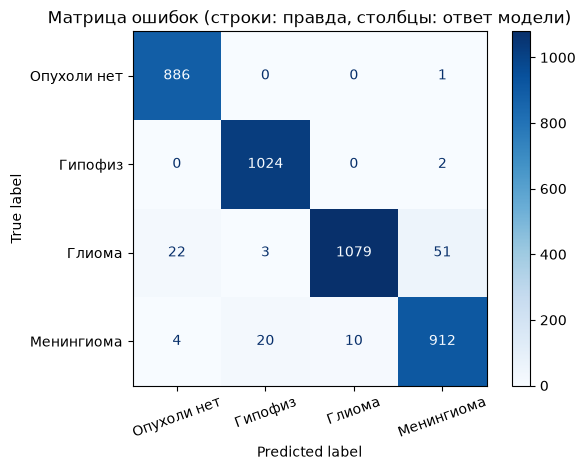

Матрица ошибок в % внутри настоящего класса:
             Опухоли нет  Гипофиз  Глиома  Менингиома
Опухоли нет         99.9      0.0     0.0         0.1
Гипофиз              0.0     99.8     0.0         0.2
Глиома               1.9      0.3    93.4         4.4
Менингиома           0.4      2.1     1.1        96.4

=== AUC (среднее по классам): 0.997
  Опухоли нет: 0.999
  Гипофиз: 1.000
  Глиома: 0.994
  Менингиома: 0.996

=== Опухоль / нет опухоли ===
Чувствительность: 0.992  (пропущено 26 из 3127)
Специфичность:    0.999  (ложных тревог 1 из 887)
AUC опухоль/нет:  0.999
   fold  accuracy  f1_macro  auc_ovr_macro
0     1  0.963129  0.963695       0.996656
1     2  0.970354  0.970694       0.996612
2     3  0.970105  0.970618       0.996798
3     4  0.965869  0.966460       0.997018
4     5  0.971849  0.972146       0.997295


In [26]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix, classification_report, make_scorer, precision_score, recall_score, ConfusionMatrixDisplay

CLASS_NAMES = ['Опухоли нет', 'Гипофиз', 'Глиома', 'Менингиома']   # порядок = метки 0..3


def to_np(t):
    t = t.as_tensor() if hasattr(t, 'as_tensor') else t
    return t.detach().cpu().numpy()


# 1. загрузить лучшую модель (она сохранена в цикле обучения)
fold_evaluations = []

for fold, weights in enumerate(fold_results):
    model = create_model().to(device)
    model.load_state_dict(weights)
    model.eval()

    # Здесь оцениваешь модель на тестовых данных

# 2. прогнать тест
    all_probs, all_labels = [], []
    with torch.no_grad():
        for images, labels in test_loader:
            outputs = model(images.to(device))
            all_probs.append(to_np(torch.softmax(outputs, dim=1)))   # вероятности классов
            all_labels.append(to_np(labels))
    y_prob = np.concatenate(all_probs)       # [N, 4]
    y_true = np.concatenate(all_labels)      # [N]
    y_pred = y_prob.argmax(axis=1)

    #фиксация результатов фолда
    try:
        auc = roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro")
    except ValueError:
        auc = np.nan

    metrics = {
        "fold": fold + 1,
        "accuracy": accuracy_score(y_true, y_pred),
       # "balanced_accuracy": 
       # "precision_macro":
       # "recall_macro": 
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "auc_ovr_macro": auc
    }

    fold_evaluations.append({
        "metrics": metrics,
        "y_true": y_true.copy(),
        "y_pred": y_pred.copy(),
        "y_prob": y_prob.copy()
    })

    print(f"\nФолд {fold + 1}")
    print([metrics])

# 3. отчёт по классам
    print("=== Отчёт по классам ===")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=3))

    # 4. матрица ошибок
    cm = confusion_matrix(y_true, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(cmap='Blues', xticks_rotation=20)
    plt.title('Матрица ошибок (строки: правда, столбцы: ответ модели)')
    plt.tight_layout()
    plt.show()

    print("Матрица ошибок в % внутри настоящего класса:")
    print(pd.DataFrame(cm / cm.sum(axis=1, keepdims=True) * 100,
                    index=CLASS_NAMES, columns=CLASS_NAMES).round(1))

    # 5. AUC
    print(f"\n=== AUC (среднее по классам): {roc_auc_score(y_true, y_prob, multi_class='ovr'):.3f}")
    for k, name in enumerate(CLASS_NAMES):
        print(f"  {name}: {roc_auc_score((y_true == k).astype(int), y_prob[:, k]):.3f}")

    # 6. самое важное для медицины: опухоль / нет опухоли
    is_tumor = y_true > 0
    pred_tumor = y_pred > 0
    missed = int((~pred_tumor & is_tumor).sum())
    false_alarm = int((pred_tumor & ~is_tumor).sum())
    print("\n=== Опухоль / нет опухоли ===")
    print(f"Чувствительность: {1 - missed / is_tumor.sum():.3f}  (пропущено {missed} из {is_tumor.sum()})")
    print(f"Специфичность:    {1 - false_alarm / (~is_tumor).sum():.3f}  (ложных тревог {false_alarm} из {(~is_tumor).sum()})")
    print(f"AUC опухоль/нет:  {roc_auc_score(is_tumor, 1 - y_prob[:, 0]):.3f}")


#таблица по метрикам фолдов
metrics_df = pd.DataFrame([result["metrics"] for result in fold_evaluations])
print(metrics_df)

metrics_df.to_csv("fold_comparison.csv", index=False)